In [1]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
from sldata import SessionData

In [2]:
base_path = "d:/data/"
mouse_id = "7012"
session_id = "m10"
experiment = "clickbait-motivate"
cluster = 19

In [3]:
data = SessionData(
    base_path=base_path,
    mouse_id=mouse_id,
    session_id=session_id,
    experiment=experiment,
    min_spikes=50,
    verbose=True)

Successfully loaded spike_times from d:\data\clickbait-motivate\kilosorted\7012\m10\spike_times.npy
Successfully loaded spike_templates from d:\data\clickbait-motivate\kilosorted\7012\m10\spike_templates.npy
Successfully loaded templates from d:\data\clickbait-motivate\kilosorted\7012\m10\templates.npy
Successfully loaded sniff from d:\data\clickbait-motivate\preprocessed\7012\m10\sniff.npy
Loaded data: ['spike_times', 'spike_templates', 'templates', 'sniff']
Successfully loaded events from d:\data\clickbait-motivate\events\7012\m10\events.csv
Video properties: 888x1968, 30.0 FPS, 81815 frames
Loaded cluster labels: 21 good, 23 mua, 14 noise
Excluded 14 noise clusters
Found 22863 peaks in sniff signal
Peak times range: 2.7 - 91559.2 ms
Loaded 43 clusters for 7012_m10
Loaded sniff data: 2746860 samples
Found 22863 sniff events


In [4]:
data.clusters[cluster]

{'cluster_id': 29,
 'label': 'good',
 'best_channel': np.int64(12),
 'spike_times': array([2.99766667e+02, 3.07933333e+02, 3.88233333e+02, ...,
        2.74556137e+06, 2.74557727e+06, 2.74562327e+06], shape=(2904,)),
 'waveform_template': array([-0.3688165 , -0.37066057, -0.35259974, -0.3234678 , -0.30130997,
        -0.31879613, -0.3383137 , -0.3349903 , -0.304613  , -0.31347868,
        -0.34181064, -0.27979487,  0.02406988,  0.47445625,  0.6799    ,
         0.34469128,  0.1223195 ,  1.5352821 ,  5.2667394 ,  9.581572  ,
        11.146077  ,  8.044255  ,  2.2392688 , -2.4798532 , -4.507581  ,
        -4.1933928 , -3.34163   , -3.0451443 , -3.1506035 , -3.1396463 ,
        -2.8204958 , -2.3675332 , -1.9595174 , -1.6309292 , -1.3264658 ,
        -1.0174693 , -0.7060964 , -0.4487006 , -0.23178606, -0.06453174,
         0.08015639,  0.19366097,  0.2819422 ,  0.33268687,  0.3471884 ,
         0.3335721 ,  0.30200422,  0.27562305,  0.260235  ,  0.24475165,
         0.22690797,  0.2104142 

In [39]:
cluster_id = data.clusters[cluster]['cluster_id']
best_channel = data.clusters[cluster_id]['best_channel']
mua = np.load(f"{base_path}{experiment}/preprocessed/{mouse_id}/{session_id}/mua.npy")
lfp = mua[best_channel,:]

In [65]:
# Load LFP
cluster_id = data.clusters[cluster]['cluster_id']
best_channel = data.clusters[cluster_id]['best_channel']
mua = np.load(f"{base_path}{experiment}/preprocessed/{mouse_id}/{session_id}/lfp.npy")
lfp = mua[1,:]

# Get PSD - use 'density' to see power law behavior
f, Pxx_spec = signal.welch(lfp, 1000, nperseg=2048, scaling='density')

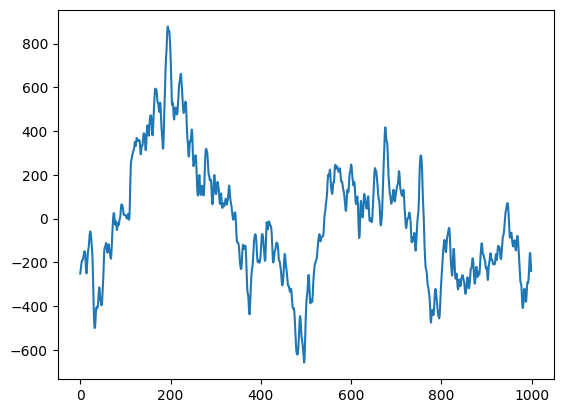

In [69]:
plt.plot(lfp[:1000])

### PSD

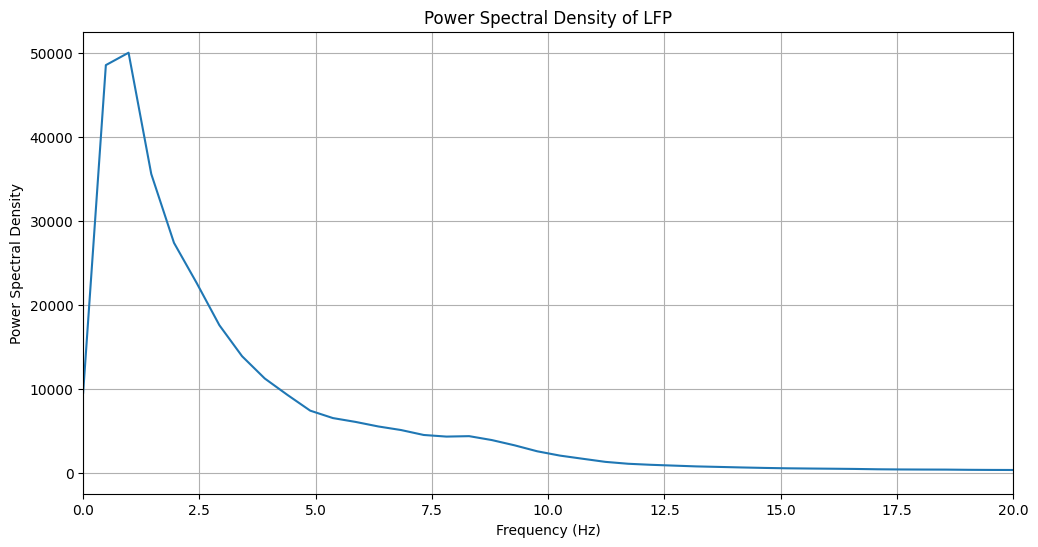

In [77]:
plt.figure(figsize=(12, 6))
plt.plot(f, Pxx_spec)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power Spectral Density')
plt.title('Power Spectral Density of LFP')
plt.grid(True)
plt.xlim(0, 20)  # Focus on frequencies up to 100 Hz
plt.show()

In [75]:
start = data.events['timestamp_ms'].iloc[0]
stop = data.events['timestamp_ms'].iloc[-1]
print(f"Events Start: {start}, Stop: {stop}, LFP Length: {len(lfp)}")

# Trim lfp to match event timestamps
lfp = lfp[start:stop]
print(f"Trimmed LFP Length: {len(lfp)}")

Events Start: 8619, Stop: 2735712, LFP Length: 2746860
Trimmed LFP Length: 2727093


In [78]:
data.events['speed']

0          0.000000
1        247.103210
2          6.000000
3          8.000000
4          7.211102
            ...    
81809      2.828427
81810      2.000000
81811     11.661903
81812     14.142136
81813     18.867962
Name: speed, Length: 81814, dtype: float64

### Theta Power vs Speed Regression

In [82]:
# Extract theta band power (4-12 Hz)
sos_theta = signal.butter(3, [4, 12], 'bandpass', fs=1000, output='sos')
theta_filtered = signal.sosfiltfilt(sos_theta, lfp)

# Get instantaneous power using Hilbert transform
analytic_signal = signal.hilbert(theta_filtered)
theta_power = np.abs(analytic_signal) ** 2

# Smooth the power with a moving average to reduce noise
window_size = 100  # 100ms window
theta_power_smooth = np.convolve(theta_power, np.ones(window_size)/window_size, mode='same')

In [93]:
# Calculate speed from nose position
nose_x = data.events['nose_x'].values
nose_y = data.events['nose_y'].values
timestamps = data.events['timestamp_ms'].values.astype(int)

# Calculate displacement between consecutive frames
dx = np.diff(nose_x)
dy = np.diff(nose_y)
dt = np.diff(timestamps) / 1000  # Convert to seconds

# Calculate speed (Euclidean distance / time)
displacement = np.sqrt(dx**2 + dy**2)
speed = displacement / dt  # pixels per second

# Prepend a 0 for the first frame (no previous position)
speed = np.concatenate([[0], speed])

# Remove outliers (>3 sigma) and replace with interpolated values
mean_speed = np.mean(speed)
std_speed = np.std(speed)
outlier_threshold = mean_speed + 3 * std_speed
outlier_mask = speed > outlier_threshold
n_outliers = np.sum(outlier_mask)

print(f"Found {n_outliers} outliers ({100*n_outliers/len(speed):.2f}%) above {outlier_threshold:.2f} pixels/s")

# Interpolate outlier values
if n_outliers > 0:
    # Get indices of valid and outlier points
    valid_indices = np.where(~outlier_mask)[0]
    outlier_indices = np.where(outlier_mask)[0]
    
    # Interpolate using valid points
    speed[outlier_indices] = np.interp(outlier_indices, valid_indices, speed[valid_indices])
    print(f"Replaced outliers with interpolated values")

# Sample theta_power at event timestamps
# Make sure timestamps are within bounds
valid_mask = timestamps < len(theta_power_smooth)
timestamps_valid = timestamps[valid_mask]
speed_aligned = speed[valid_mask]
theta_power_aligned = theta_power_smooth[timestamps_valid]

print(f"\nData points: {len(theta_power_aligned)}")
print(f"Sampling rate of events: ~{len(data.events) / (timestamps[-1] / 1000):.1f} Hz")
print(f"Speed range: {np.min(speed_aligned):.2f} - {np.max(speed_aligned):.2f} pixels/s")
print(f"Theta power range: {np.min(theta_power_aligned):.2e} - {np.max(theta_power_aligned):.2e}")

Found 997 outliers (1.22%) above 2436.02 pixels/s
Replaced outliers with interpolated values

Data points: 81555
Sampling rate of events: ~29.9 Hz
Speed range: 0.00 - 2435.32 pixels/s
Theta power range: 2.58e+01 - 3.90e+06


In [97]:
# Remove NaN values
mask = ~(np.isnan(theta_power_aligned) | np.isnan(speed_aligned))
theta_power_clean = theta_power_aligned[mask]
speed_clean = speed_aligned[mask]

# Filter out low speeds (< 2 cm/s ≈ 100 pixels/s)
min_speed = 100  # pixels/s, approximately 2 cm/s
speed_mask = speed_clean >= min_speed
speed_filtered = speed_clean[speed_mask]
theta_filtered = theta_power_clean[speed_mask]

print(f"Removed {np.sum(~speed_mask)} low-speed points ({100*np.sum(~speed_mask)/len(speed_clean):.1f}%)")
print(f"Remaining data points for regression: {len(speed_filtered)}")

# Perform linear regression on filtered data
from scipy.stats import linregress
slope, intercept, r_value, p_value, std_err = linregress(speed_filtered, theta_filtered)

print(f"\nRegression Results (speed ≥ {min_speed} pixels/s):")
print(f"Slope: {slope:.2e}")
print(f"Intercept: {intercept:.2e}")
print(f"R²: {r_value**2:.4f}")
print(f"p-value: {p_value:.2e}")

Removed 19816 low-speed points (24.3%)
Remaining data points for regression: 61739

Regression Results (speed ≥ 100 pixels/s):
Slope: 3.34e+01
Intercept: 4.93e+04
R²: 0.0062
p-value: 2.42e-85


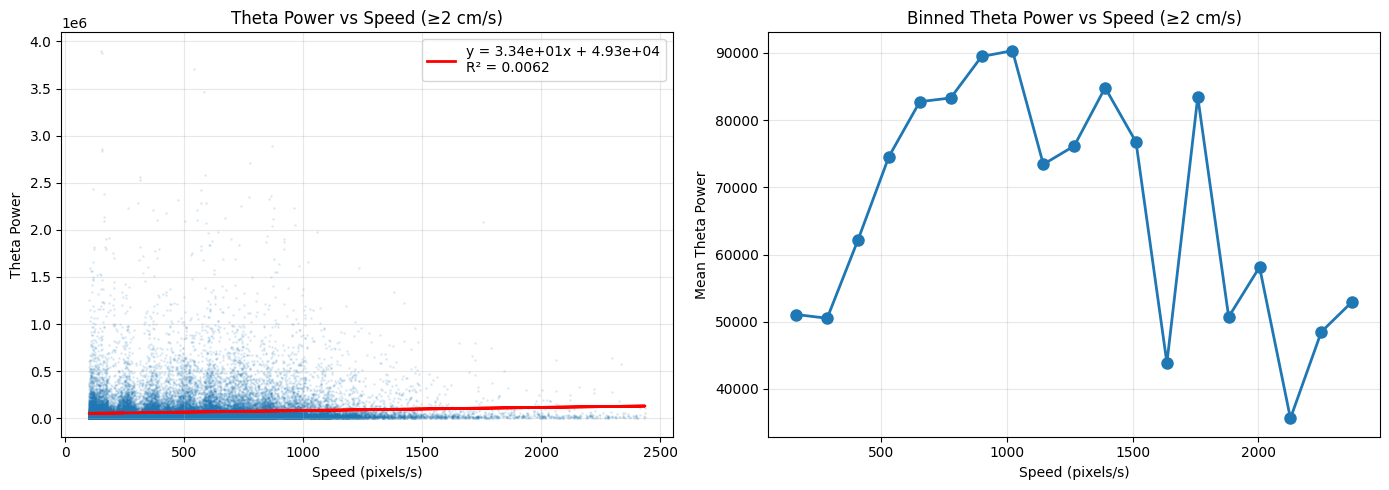

In [102]:
# Plot the relationship
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot with regression line
ax1 = axes[0]
ax1.scatter(speed_filtered, theta_filtered, alpha=0.1, s=1)
ax1.plot(speed_filtered, slope * speed_filtered + intercept, 'r-', linewidth=2, 
         label=f'y = {slope:.2e}x + {intercept:.2e}\nR² = {r_value**2:.4f}')
ax1.set_xlabel('Speed (pixels/s)')
ax1.set_ylabel('Theta Power')
ax1.set_title('Theta Power vs Speed (≥2 cm/s)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Binned average plot for clearer visualization
ax2 = axes[1]
n_bins = 20
speed_bins = np.linspace(np.min(speed_filtered), np.max(speed_filtered), n_bins)
bin_indices = np.digitize(speed_filtered, speed_bins)
binned_theta = [theta_filtered[bin_indices == i].mean() for i in range(1, n_bins) if np.sum(bin_indices == i) > 0]
binned_speed = [(speed_bins[i-1] + speed_bins[i])/2 for i in range(1, n_bins) if np.sum(bin_indices == i) > 0]

ax2.plot(binned_speed, binned_theta, 'o-', linewidth=2, markersize=8)
ax2.set_xlabel('Speed (pixels/s)')
ax2.set_ylabel('Mean Theta Power')
ax2.set_title('Binned Theta Power vs Speed (≥2 cm/s)')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()